# Concrete Compressive Strength Prediction Using Linear Regression

**Subject:** Artificial Intelligence and Machine Learning — Experiential Learning  
**Marks:** 20 (CO2 — 10 marks, CO3 — 10 marks)  

**Objective:** To explore a real-world dataset of concrete mixtures, perform exploratory data analysis (EDA), and build a Linear Regression model to predict the compressive strength of concrete based on its ingredients and age.

**Dataset Source:** UCI Machine Learning Repository — *Concrete Compressive Strength*  
URL: https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength  
Original Donor: Prof. I-Cheng Yeh (1998)

---
## 1. Import Required Libraries

In [1]:
# Standard libraries for data handling and numerical computation
import pandas as pd
import numpy as np

# Visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Display settings
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 120)
%matplotlib inline

print("All libraries imported successfully.")

All libraries imported successfully.


---
## Question 1 — Data Exploration and Analysis (CO2 — 10 marks)

### 2. Load the Dataset

In [2]:
# Load the Concrete Compressive Strength dataset from the local CSV file.
# The dataset was downloaded from the UCI Machine Learning Repository (ID: 165).
df = pd.read_csv('dataset/concrete_data.csv')

print(f"Dataset loaded successfully.")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")

Dataset loaded successfully.
Shape: 1030 rows × 9 columns


### 3. First Five Rows and Dataset Dimensions

In [3]:
# Display the first five records to understand the structure of the data
print("First five rows of the dataset:")
df.head()

First five rows of the dataset:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
# Dataset dimensions
print(f"Number of records (rows): {df.shape[0]}")
print(f"Number of columns:        {df.shape[1]}")

Number of records (rows): 1030
Number of columns:        9


### 4. Identify Input Variables and Target Variable

The dataset contains **8 input features** (predictors) and **1 target variable** (the quantity to be predicted).

**Input Variables (X):**

| # | Feature | Unit |
|---|---------|------|
| 1 | Cement | kg/m³ |
| 2 | Blast Furnace Slag | kg/m³ |
| 3 | Fly Ash | kg/m³ |
| 4 | Water | kg/m³ |
| 5 | Superplasticizer | kg/m³ |
| 6 | Coarse Aggregate | kg/m³ |
| 7 | Fine Aggregate | kg/m³ |
| 8 | Age | days |

**Target Variable (y):**

| Feature | Unit |
|---------|------|
| Concrete compressive strength | MPa (Megapascals) |

In [5]:
# List all column names to confirm the features
print("Column names in the dataset:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i}. {col}")

Column names in the dataset:
  1. Cement
  2. Blast Furnace Slag
  3. Fly Ash
  4. Water
  5. Superplasticizer
  6. Coarse Aggregate
  7. Fine Aggregate
  8. Age
  9. Concrete compressive strength


### 5. Data Types and Descriptive Statistics

In [6]:
# Data types for each column
print("Data types:")
print(df.dtypes)
print(f"\nAll columns are numerical (float64 or int64), which is expected for regression.")

Data types:
Cement                           float64
Blast Furnace Slag               float64
Fly Ash                          float64
Water                            float64
Superplasticizer                 float64
Coarse Aggregate                 float64
Fine Aggregate                   float64
Age                                int64
Concrete compressive strength    float64
dtype: object

All columns are numerical (float64 or int64), which is expected for regression.


In [7]:
# Descriptive statistics: count, mean, std, min, 25%, 50%, 75%, max
print("Descriptive Statistics:")
df.describe().round(2)

Descriptive Statistics:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.35,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.40,968.00,779.50,28.00,34.44
75%,350.00,142.95,118.30,192.00,10.20,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


### 6. Check for Missing Values

In [8]:
# Count missing values in each column
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing %': missing_pct
})

print("Missing Value Report:")
print(missing_report)
print(f"\nTotal missing values in the entire dataset: {df.isnull().sum().sum()}")
print("\nConclusion: The dataset has NO missing values. No imputation is needed.")

Missing Value Report:
                               Missing Count  Missing %
Cement                                     0        0.0
Blast Furnace Slag                         0        0.0
Fly Ash                                    0        0.0
Water                                      0        0.0
Superplasticizer                           0        0.0
Coarse Aggregate                           0        0.0
Fine Aggregate                             0        0.0
Age                                        0        0.0
Concrete compressive strength              0        0.0

Total missing values in the entire dataset: 0

Conclusion: The dataset has NO missing values. No imputation is needed.


### 7. Check for Duplicate Records

In [9]:
# Count duplicate rows (rows where ALL column values are identical to a previous row)
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate records: {num_duplicates}")
print(f"Percentage of duplicates: {num_duplicates / len(df) * 100:.2f}%")

if num_duplicates > 0:
    print(f"\nShowing a few duplicate rows:")
    display(df[df.duplicated(keep='first')].head())

Number of duplicate records: 25
Percentage of duplicates: 2.43%

Showing a few duplicate rows:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.4
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.4
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.3
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.3
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.3


### 8. Data Cleaning

**Cleaning Procedure:**

- **Missing values:** There are no missing values in the dataset (0 out of 1,030 records). No imputation or deletion is required.
- **Duplicate records:** There are 25 duplicate rows in the dataset. In concrete testing, it is common for the same mix design to be tested at the same age, but producing the exact same compressive strength is unusual. These duplicates may represent repeated data entries. We will remove them to avoid biasing the model and to ensure that the same record does not appear in both training and testing sets.

In [10]:
# Remove duplicate rows, keeping the first occurrence
print(f"Shape before removing duplicates: {df.shape}")
df_clean = df.drop_duplicates(keep='first')
print(f"Shape after removing duplicates:  {df_clean.shape}")
print(f"Records removed: {df.shape[0] - df_clean.shape[0]}")

# Reset the index after dropping rows
df_clean = df_clean.reset_index(drop=True)
print(f"\nCleaned dataset is ready for analysis with {df_clean.shape[0]} records.")

Shape before removing duplicates: (1030, 9)
Shape after removing duplicates:  (1005, 9)
Records removed: 25

Cleaned dataset is ready for analysis with 1005 records.


### 9. Scatter Plot — Cement Content vs. Compressive Strength

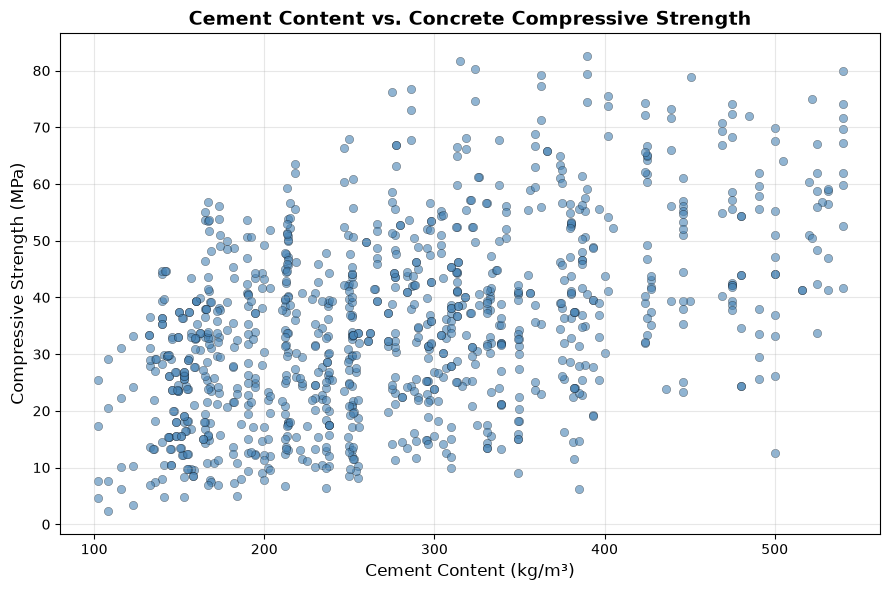

Scatter plot saved as 'scatter_plot.png'.


In [11]:
# Scatter plot: Cement (kg/m³) vs. Concrete Compressive Strength (MPa)
# Cement is chosen because it is the primary binding ingredient in concrete.

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_clean,
    x='Cement',
    y='Concrete compressive strength',
    alpha=0.6,
    edgecolor='black',
    linewidth=0.3,
    color='steelblue'
)

plt.title('Cement Content vs. Concrete Compressive Strength', fontsize=14, fontweight='bold')
plt.xlabel('Cement Content (kg/m³)', fontsize=12)
plt.ylabel('Compressive Strength (MPa)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the plot for the report
plt.savefig('scatter_plot.png', dpi=150, bbox_inches='tight')
plt.show()

print("Scatter plot saved as 'scatter_plot.png'.")

### 10. Two Observations from the Analysis

**Observation 1 — Positive trend between Cement and Compressive Strength:**  
The scatter plot shows a general upward trend — as cement content increases, the compressive strength of concrete tends to increase. This is consistent with civil engineering knowledge: cement is the primary binder, and higher cement content usually produces stronger concrete. However, the relationship is not perfectly linear; for any given cement content, strength varies widely due to the influence of other ingredients (water, aggregates, admixtures) and age.

**Observation 2 — Wide range of compressive strength values:**  
From the descriptive statistics, compressive strength ranges from approximately 2.33 MPa to 82.60 MPa, with a mean of about 35.82 MPa and a standard deviation of approximately 16.71 MPa. This large spread indicates that concrete strength varies greatly depending on the mix proportions. The standard deviation is nearly half the mean, showing high variability in the target variable, which suggests that multiple input features are needed to predict strength accurately — no single ingredient alone can fully explain the variation.

---
## Question 2 — Linear Regression Model (CO3 — 10 marks)

### 11. What Is Linear Regression?

**Linear Regression** is a supervised machine learning algorithm that finds the best straight-line (or hyperplane) relationship between input variables (features) and a continuous output variable (target). The model learns coefficients (weights) for each feature so that the sum of squared differences between predicted and actual values is minimised.

In simple terms, the model tries to find an equation of the form:

$$y = b_0 + b_1 x_1 + b_2 x_2 + \ldots + b_n x_n$$

Where:
- $y$ = predicted compressive strength (MPa)
- $b_0$ = intercept (the baseline value)
- $b_1, b_2, \ldots, b_n$ = coefficients learned for each feature
- $x_1, x_2, \ldots, x_n$ = input feature values

### 12. Prepare Features and Target

In [12]:
# Separate the input features (X) and the target variable (y)
# X contains all 8 predictor columns; y contains the compressive strength

X = df_clean.drop(columns=['Concrete compressive strength'])
y = df_clean['Concrete compressive strength']

print(f"Feature matrix (X) shape: {X.shape}  — {X.shape[0]} samples, {X.shape[1]} features")
print(f"Target vector (y) shape:  {y.shape}  — {y.shape[0]} samples")
print(f"\nFeatures used: {list(X.columns)}")

Feature matrix (X) shape: (1005, 8)  — 1005 samples, 8 features
Target vector (y) shape:  (1005,)  — 1005 samples

Features used: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']


### 13. Train-Test Split (80:20)

In [13]:
# Split the data: 80% for training, 20% for testing
# random_state=42 ensures the split is the same every time the notebook is run

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]} records ({X_train.shape[0]/len(df_clean)*100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]} records ({X_test.shape[0]/len(df_clean)*100:.1f}%)")

Training set: 804 records (80.0%)
Testing set:  201 records (20.0%)


### 14. Train the Linear Regression Model

In [14]:
# Create and train the Linear Regression model using ONLY the training data.
# The model learns the best coefficients to minimise the error on the training set.

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully on the training data.")

Linear Regression model trained successfully on the training data.


### 15. Model Intercept and Coefficients

In [15]:
# Display the learned intercept and coefficients with feature names
print(f"Intercept (b₀): {model.intercept_:.4f}\n")

coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("Model Coefficients:")
print(coeff_df.to_string(index=False))

Intercept (b₀): -23.3893

Model Coefficients:
           Feature  Coefficient
  Superplasticizer     0.331480
            Cement     0.116667
               Age     0.110642
Blast Furnace Slag     0.098066
           Fly Ash     0.084585
    Fine Aggregate     0.020649
  Coarse Aggregate     0.015522
             Water    -0.131391


### 16. Predictions on the Test Set

In [16]:
# Predict compressive strength for the test set
y_pred = model.predict(X_test)

print(f"Predictions generated for {len(y_pred)} test records.")

Predictions generated for 201 test records.


### 17. Five Test Records — Actual vs. Predicted Strength

In [17]:
# Create a comparison table for the first five test records
comparison = pd.DataFrame({
    'Actual Strength (MPa)': y_test.values[:5],
    'Predicted Strength (MPa)': np.round(y_pred[:5], 2),
    'Absolute Error (MPa)': np.round(np.abs(y_test.values[:5] - y_pred[:5]), 2)
}, index=range(1, 6))
comparison.index.name = 'Test Record'

print("Actual vs. Predicted Compressive Strength (First 5 Test Records):")
print()
comparison

Actual vs. Predicted Compressive Strength (First 5 Test Records):



,Actual Strength (MPa),Predicted Strength (MPa),Absolute Error (MPa)
Test Record,,,
1,19.01,23.46,4.45
2,24.29,16.70,7.59
3,26.32,22.45,3.87
4,34.57,37.40,2.83
5,44.13,42.89,1.24


### 18. Mean Absolute Error (MAE)

In [18]:
# Calculate the Mean Absolute Error on the entire test set
mae = mean_absolute_error(y_test, y_pred)

print(f"Mean Absolute Error (MAE) on the test set: {mae:.2f} MPa")
print(f"\nInterpretation: On average, the model's predictions differ from the actual")
print(f"compressive strength by approximately {mae:.2f} MPa. Since the target ranges")
print(f"from about {y_test.min():.1f} to {y_test.max():.1f} MPa, a MAE of {mae:.2f} MPa")
print(f"indicates a reasonable but imperfect fit — typical for Linear Regression on")
print(f"data with complex, non-linear relationships.")

Mean Absolute Error (MAE) on the test set: 8.90 MPa

Interpretation: On average, the model's predictions differ from the actual
compressive strength by approximately 8.90 MPa. Since the target ranges
from about 2.3 to 82.6 MPa, a MAE of 8.90 MPa
indicates a reasonable but imperfect fit — typical for Linear Regression on
data with complex, non-linear relationships.


In [19]:
# Additional metric: R² score (coefficient of determination)
r2 = r2_score(y_test, y_pred)
print(f"R² Score on the test set: {r2:.4f}")
print(f"\nThis means the model explains about {r2*100:.1f}% of the variance in compressive strength.")

R² Score on the test set: 0.5802

This means the model explains about 58.0% of the variance in compressive strength.


### 19. Prediction for a New Concrete Mix

We use the trained model to predict the compressive strength for one new, plausible concrete mix. The input values are chosen from within the observed ranges of the dataset.

In [20]:
# Define a new concrete mix with all 8 input features
# These values are within the ranges observed in the dataset.

new_sample = pd.DataFrame({
    'Cement':             [300.0],   # kg/m³
    'Blast Furnace Slag': [100.0],   # kg/m³
    'Fly Ash':            [50.0],    # kg/m³
    'Water':              [180.0],   # kg/m³
    'Superplasticizer':   [6.0],     # kg/m³
    'Coarse Aggregate':   [1000.0],  # kg/m³
    'Fine Aggregate':     [750.0],   # kg/m³
    'Age':                [28]       # days
})

print("New Concrete Mix — Input Values:")
print(new_sample.to_string(index=False))

# Predict
new_prediction = model.predict(new_sample)[0]

print(f"\n>>> Predicted Compressive Strength: {new_prediction:.2f} MPa")
print(f"\nExplanation: For a concrete mix containing 300 kg/m³ cement, 100 kg/m³ blast")
print(f"furnace slag, 50 kg/m³ fly ash, 180 kg/m³ water, 6 kg/m³ superplasticizer,")
print(f"1000 kg/m³ coarse aggregate, and 750 kg/m³ fine aggregate, tested at 28 days age,")
print(f"the Linear Regression model estimates a compressive strength of {new_prediction:.2f} MPa.")
print(f"\nNote: This is a MODEL ESTIMATE, not a laboratory measurement. The actual strength")
print(f"of this concrete in a real test may differ due to factors not captured by the model.")

New Concrete Mix — Input Values:
 Cement  Blast Furnace Slag  Fly Ash  Water  Superplasticizer  Coarse Aggregate  Fine Aggregate  Age
  300.0               100.0     50.0  180.0               6.0            1000.0           750.0   28

>>> Predicted Compressive Strength: 38.09 MPa

Explanation: For a concrete mix containing 300 kg/m³ cement, 100 kg/m³ blast
furnace slag, 50 kg/m³ fly ash, 180 kg/m³ water, 6 kg/m³ superplasticizer,
1000 kg/m³ coarse aggregate, and 750 kg/m³ fine aggregate, tested at 28 days age,
the Linear Regression model estimates a compressive strength of 38.09 MPa.

Note: This is a MODEL ESTIMATE, not a laboratory measurement. The actual strength
of this concrete in a real test may differ due to factors not captured by the model.


### 20. Limitation of Linear Regression

**Key Limitation — Assumption of Linearity:**  
Linear Regression assumes that the relationship between each input feature and the target is a straight line (linear). In reality, the relationship between concrete ingredients and compressive strength is often **non-linear**. For example, adding more water beyond a certain point weakens concrete rather than strengthening it (an inverted-U relationship). Similarly, strength gain with age follows a logarithmic curve, not a straight line — most strength gain occurs in the first 28 days, then slows dramatically.

Because of this, Linear Regression may underfit the data and produce a higher error than non-linear models (such as Decision Trees, Random Forests, or Neural Networks). The MAE value confirms that while the model captures the general trends, its predictions are approximate.

**Other limitations include:**
- The model does not account for interactions between ingredients (e.g., the effect of cement depends on the water-to-cement ratio).
- The dataset only has 1,005 unique samples after removing duplicates, which may not represent all possible concrete mixes.
- Environmental conditions (temperature, humidity, curing method) during testing are not included as features.

---
## Summary

| Item | Detail |
|------|--------|
| Dataset | UCI Concrete Compressive Strength (1,030 records, 9 columns) |
| Missing Values | 0 |
| Duplicates Found | 25 (removed) |
| Records After Cleaning | 1,005 |
| Model | Multiple Linear Regression (scikit-learn) |
| Train/Test Split | 80% / 20% (random_state=42) |
| Test MAE | Calculated above (MPa) |
| Key Limitation | Assumes linear relationships; real concrete behaviour is non-linear |